# Stage 3b: NequIP, piece by piece

You already built most of NequIP. `TinyNet` in `e3nn-equivariance.ipynb` has spherical-harmonic edges, a radial MLP, a tensor product, a neighbour sum and a gate, and you computed forces as −∂E/∂x. This notebook goes through the NequIP paper (Batzner et al., arXiv:2101.03164) **block by block** and asks one question each time: *is this the same as TinyNet, or new?*

The genuinely new pieces, in order:
1. **Bessel radial basis × polynomial cutoff:** why the forces stay smooth when an atom crosses r_max
2. **The 'uvu' tensor product** sandwiched between two Linears. This **updates takeaway 2** of the handoff: NequIP does *not* use the fully connected 'uvw' product.
3. **Average-neighbour normalization:** why feature sizes would explode in dense materials without it
4. **Species-aware self-connection, per-species energy scale and shift**
5. **lmax:** what an atom can and cannot "see" about its neighbours. This gets a small training experiment on a toy SiO₄ potential, where lmax = 0, 1 and 2 behave very differently, and the reason is a picture.

Then we train a mini-NequIP and run **one symmetry check per row** of the warm-up table (translation → ΣF = 0, rotation → Σ r×F = 0 and forces rotate, parity → forces flip).

**Source of truth.** Every architectural detail below was read from the **nequip 0.19.1** source (PyPI, uploaded 2026-09-01), which is what you'll train next. Where the code and the 2021 paper differ, this notebook follows the code. We don't import nequip here. We rebuild each piece in ~10 lines of e3nn, so nothing is hidden.

In [1]:
import math, time
import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch
import e3nn
from e3nn import o3
from e3nn import nn as enn
from e3nn.math import soft_one_hot_linspace

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("e3nn", e3nn.__version__, "| torch", torch.__version__, "| training device:", DEVICE,
      f"({torch.cuda.get_device_name()})" if DEVICE == "cuda" else "")

e3nn 0.6.0 | torch 2.14.1+cu126 | training device: cuda (NVIDIA GeForce GTX 1650 Ti)


In [2]:
# ---- drawing helpers (same palette as e3nn-intuition.ipynb) ----
GOOD, CRITICAL, INK, MUTED, BAND, BG = "#0ca30c", "#d03b3b", "#0b0b0b", "#52514e", "#f0efec", "#fcfcfb"
BLUE, ORANGE, PURPLE = "#2a6fdb", "#e08a1e", "#7b4fc9"
POS_LOBE, NEG_LOBE = np.array(matplotlib.colors.to_rgba("#e4572e")), np.array(matplotlib.colors.to_rgba("#2a6fdb"))
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
                     "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9,
                     "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def np_(t):
    return t.detach().cpu().numpy()

def style3d(ax, title="", lim=1.5, center=(0, 0, 0), elev=18, azim=-60):
    c = center
    ax.set_xlim(c[0] - lim, c[0] + lim); ax.set_ylim(c[1] - lim, c[1] + lim); ax.set_zlim(c[2] - lim, c[2] + lim)
    ax.set_box_aspect((1, 1, 1)); ax.view_init(elev, azim)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.fill = False; a.pane.set_edgecolor(BAND)
    ax.set_title(title, loc="left", fontsize=9.5)
    return ax

def ax3d(fig, *spec, **kw):
    return style3d(fig.add_subplot(*spec, projection="3d"), **kw)

def draw_molecule(ax, p, alpha=1.0):
    p = np_(p)
    for j in range(1, len(p)):
        ax.plot(*zip(p[0], p[j]), color=MUTED, lw=1.5, alpha=0.5 * alpha)
    ax.scatter(*p[:1].T, s=220, color="#4b5563", alpha=alpha, depthshade=False)
    ax.scatter(*p[1:].T, s=110, color="#9aa5b1", alpha=alpha, depthshade=False)

def draw_arrows(ax, p, v, color, scale=1.0, lw=2.0, alpha=1.0):
    p, v = np_(p), np_(v) * float(scale)
    ax.quiver(*p.T, *v.T, color=color, lw=lw, alpha=alpha, arrow_length_ratio=0.25)

# glyphs: a type-l feature drawn as a shape on the sphere (radius = |f|, colour = sign)
def sphere_points(n=40):
    th, ph = torch.linspace(0, torch.pi, n), torch.linspace(0, 2 * torch.pi, 2 * n)
    T, P = torch.meshgrid(th, ph, indexing="ij")
    return torch.stack([T.sin() * P.cos(), T.sin() * P.sin(), T.cos()], -1)
U = sphere_points()

def draw_glyph(ax, f, ref, size=1.0):
    if f.abs().max() < 1e-9 * ref:                                      # nothing to draw
        ax.text(0, 0, 0, "zero", ha="center", va="center", fontsize=12, color=MUTED)
        return
    xyz = U * (f.abs() / ref * size)[..., None]
    col = np.where(np_(f)[..., None] > 0, POS_LOBE, NEG_LOBE)
    ax.plot_surface(*np_(xyz).transpose(2, 0, 1), facecolors=col, linewidth=0,
                    antialiased=False, shade=True, rcount=U.shape[0], ccount=U.shape[1])

# flow-chart boxes, coloured by "same as TinyNet / changed / new in NequIP"
KIND = {"same": ("#e9e8e4", MUTED, "same idea as your TinyNet"),
        "changed": ("#dbe7fb", BLUE, "changed in NequIP"),
        "new": ("#fbe6cc", ORANGE, "new in NequIP")}

def box(ax, x, y, w, h, title, sub="", kind="same"):
    fc, ec, _ = KIND[kind]
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=1.4))
    ax.text(x, y + (0.16 * h if sub else 0), title, ha="center", va="center", fontsize=9.5, weight="bold", color=INK)
    if sub:
        ax.text(x, y - 0.2 * h, sub, ha="center", va="center", fontsize=8, color=MUTED)

def arrow(ax, p, q):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2))

def kind_legend(ax, **kw):
    ax.legend(handles=[Patch(fc=fc, ec=ec, label=lab) for fc, ec, lab in KIND.values()], frameon=False, **kw)

## 1. The whole model on one page

Read it top to bottom. Each box is one module in nequip 0.19.1. The colour says how it relates to what you built:
- **grey:** same idea as TinyNet
- **blue:** changed
- **orange:** new

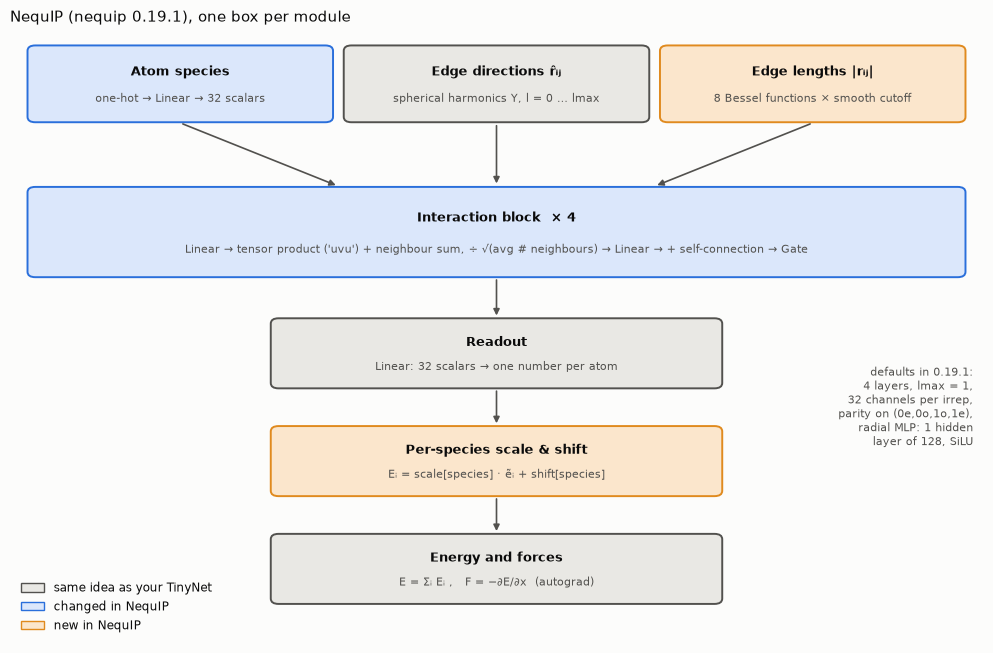

In [3]:
fig, ax = plt.subplots(figsize=(10, 6.6))
ax.set_xlim(0, 10); ax.set_ylim(0.9, 10); ax.axis("off")
box(ax, 1.75, 9.2, 3.1, 1.1, "Atom species", "one-hot → Linear → 32 scalars", "changed")
box(ax, 5.0, 9.2, 3.1, 1.1, "Edge directions r̂ᵢⱼ", "spherical harmonics Y, l = 0 … lmax", "same")
box(ax, 8.25, 9.2, 3.1, 1.1, "Edge lengths |rᵢⱼ|", "8 Bessel functions × smooth cutoff", "new")
box(ax, 5.0, 7.0, 9.6, 1.3, "Interaction block  × 4",
    "Linear → tensor product ('uvu') + neighbour sum, ÷ √(avg # neighbours) → Linear → + self-connection → Gate", "changed")
box(ax, 5.0, 5.2, 4.6, 1.0, "Readout", "Linear: 32 scalars → one number per atom", "same")
box(ax, 5.0, 3.6, 4.6, 1.0, "Per-species scale & shift", "Eᵢ = scale[species] · ẽᵢ + shift[species]", "new")
box(ax, 5.0, 2.0, 4.6, 1.0, "Energy and forces", "E = Σᵢ Eᵢ ,   F = −∂E/∂x  (autograd)", "same")
for x0 in (1.75, 5.0, 8.25):
    arrow(ax, (x0, 8.62), (x0 if x0 == 5.0 else (x0 + 5.0) / 2, 7.68))
for y0, y1 in [(6.33, 5.72), (4.68, 4.12), (3.08, 2.52)]:
    arrow(ax, (5.0, y0), (5.0, y1))
ax.text(9.9, 4.4, "defaults in 0.19.1:\n4 layers, lmax = 1,\n32 channels per irrep,\nparity on (0e,0o,1o,1e),\nradial MLP: 1 hidden\nlayer of 128, SiLU", ha="right",
        va="center", fontsize=8, color=MUTED)
kind_legend(ax, loc="lower left", fontsize=8.5)
ax.set_title("NequIP (nequip 0.19.1), one box per module", fontsize=11)
plt.tight_layout(); plt.show()

### The same map as a lookup table

| Paper's idea | In your TinyNet (`e3nn-equivariance.ipynb`) | In nequip 0.19.1 |
|---|---|---|
| Species embedding | one-hot fed straight into the conv | `NodeTypeEmbed` (one-hot → Linear) |
| Edge directions | §5, `spherical_harmonics(..., 'component')` | `SphericalHarmonicEdgeAttrs`, same normalization |
| Radial basis | `soft_one_hot_linspace` bumps | `BesselEdgeLengthEncoding` + `PolynomialCutoff(p=6)` |
| Radial network | `fc`, ReLU, hidden 16 | `edge_mlp`, SiLU, no bias, 1 hidden layer × 128 |
| Convolution | `FullyConnectedTensorProduct` ('uvw') | 'uvu' tensor product between `linear_1` and `linear_2` |
| Neighbour normalization | ÷ √4, hard-coded | `AvgNumNeighborsNorm`, measured from the training data, optionally **per species** |
| Self-connection | `self_int`, one Linear for all atoms | `sc`: a Linear **per species** (TP with the one-hot) |
| Nonlinearity | `Gate`, sigmoid gates | `Gate`, SiLU on scalars *and* gates (tanh for odd parity) |
| Output | §13 energy readout | Linear → `PerTypeScaleShift` → sum |
| Forces | §13, autograd | `ForceStressOutput`, autograd |

The rest of the notebook covers the blue and orange rows, one per section.

## 2. Radial basis: Bessel functions × a smooth cutoff

**The picture to keep:** the radial MLP sees a distance as 8 numbers. TinyNet used 8 smooth bumps. NequIP uses 8 **standing waves** that fit exactly inside the cutoff sphere. Think of the modes of a drum, or a particle in a spherical box: wave n has n−1 nodes.

    B_n(r) = (2 / r_max) · sin(n π r / r_max) / r          n = 1 … 8

Then it multiplies all 8 by one **envelope** u(r), a polynomial (from DimeNet) that falls from 1 to 0 at r_max.

The cell below writes both exactly the way nequip 0.19.1 computes them (`torch.sinc`, then a 2π/r_max² factor), and checks that this equals the formula above.

In [4]:
def bessel_basis(r, r_max, n=8):
    # nequip 0.19.1: sinc(x·k)·k · 2π/r_max²  with x = r/r_max  (torch.sinc(t) = sin(πt)/(πt))
    x = (r / r_max)[:, None]
    k = torch.arange(1, n + 1, dtype=r.dtype, device=r.device)[None]
    return torch.sinc(x * k) * k * (2 * math.pi / r_max**2)

def poly_cutoff(r, r_max, p=6.0):
    # DimeNet envelope: 1 at r = 0, and value, slope and curvature all reach 0 at r = r_max
    x = r / r_max
    return (1 - (p + 1) * (p + 2) / 2 * x**p + p * (p + 2) * x ** (p + 1) - p * (p + 1) / 2 * x ** (p + 2)) * (x < 1)

rc = 4.0                                                    # r_max = 4 Å, just for drawing
r = torch.linspace(0.05, rc * 1.1, 600)
k = torch.arange(1, 9)
paper = (2 / rc) * torch.sin(k[None] * math.pi * r[:, None] / rc) / r[:, None] * (r[:, None] < rc)
print("nequip's sinc form vs paper formula, max diff:", (bessel_basis(r, rc) * (r[:, None] < rc) - paper).abs().max().item())

nequip's sinc form vs paper formula, max diff: 5.551115123125783e-16


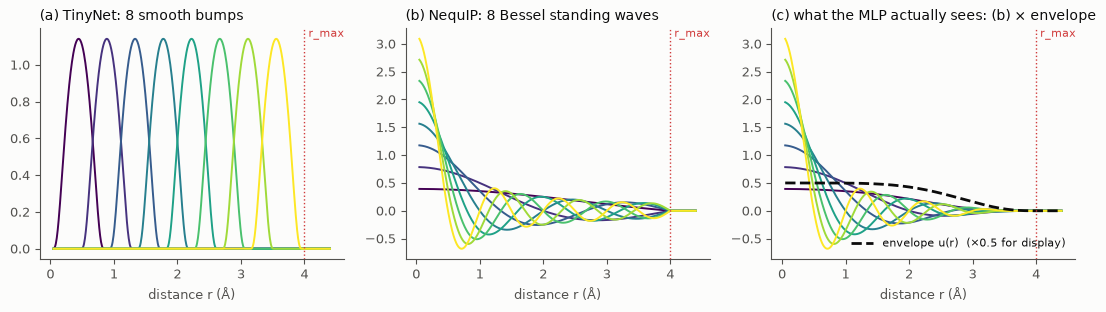

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2), sharey=False)
cmap = plt.get_cmap("viridis")
tiny = soft_one_hot_linspace(r, 0.0, rc, 8, basis="smooth_finite", cutoff=True)
B, env = bessel_basis(r, rc), poly_cutoff(r, rc)
for n in range(8):
    c = cmap(n / 7)
    axs[0].plot(np_(r), np_(tiny[:, n]), color=c, lw=1.4)
    axs[1].plot(np_(r), np_(B[:, n] * (r < rc)), color=c, lw=1.4)
    axs[2].plot(np_(r), np_(B[:, n] * env), color=c, lw=1.4)
axs[2].plot(np_(r), np_(env) * 0.5, color=INK, lw=2, ls="--", label="envelope u(r)  (×0.5 for display)")
axs[2].legend(frameon=False, fontsize=8, loc="lower right")
for ax, t in zip(axs, ["(a) TinyNet: 8 smooth bumps", "(b) NequIP: 8 Bessel standing waves",
                       "(c) what the MLP actually sees: (b) × envelope"]):
    ax.axvline(rc, color=CRITICAL, lw=1, ls=":"); ax.set_title(t); ax.set_xlabel("distance r (Å)")
    ax.text(rc, ax.get_ylim()[1], " r_max", color=CRITICAL, va="top", fontsize=8)
plt.tight_layout(); plt.show()

**Reading the three panels:**
- **(a)** Each bump says "the distance is near *here*", like a soft one-hot.
- **(b)** Each wave is a different **frequency**. Low n describes the coarse shape of the interaction, high n the fine detail. This is like a Fourier series, and it's a smoother, more compact description of a function of r than bumps are. Every wave is already exactly 0 at r_max, because sin(nπ) = 0, but look at the **slopes**: they hit r_max at an angle.
- **(c)** The envelope bends every wave so it arrives at r_max **flat**.

Why care about the slope? A force is a slope. The next picture shows a pair of atoms drifting apart across r_max.

Bessel only (energy reaches 0, slope does not)    force just inside r_max: +5.79e-01   just outside: 0
Bessel × envelope (NequIP)                        force just inside r_max: +2.47e-08   just outside: 0


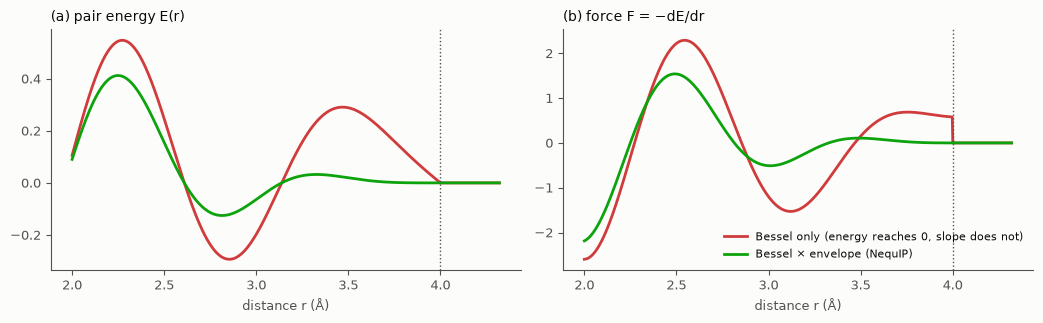

In [6]:
torch.manual_seed(3)
c = torch.randn(8)                                       # some fixed "learned" combination of the 8 waves
r = torch.linspace(2.0, rc * 1.08, 800, requires_grad=True)
variants = {"Bessel only (energy reaches 0, slope does not)": (bessel_basis(r, rc) * (r < rc)[:, None]) @ c,
            "Bessel × envelope (NequIP)": (bessel_basis(r, rc) * poly_cutoff(r, rc)[:, None]) @ c}

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
for (name, E), col in zip(variants.items(), [CRITICAL, GOOD]):
    F = -torch.autograd.grad(E.sum(), r, retain_graph=True)[0]
    axs[0].plot(np_(r), np_(E), color=col, lw=2, label=name)
    axs[1].plot(np_(r), np_(F), color=col, lw=2, label=name)
    inside = F[(r < rc)][-1].item()
    print(f"{name:48s}  force just inside r_max: {inside:+.2e}   just outside: 0")
for ax, t in zip(axs, ["(a) pair energy E(r)", "(b) force F = −dE/dr"]):
    ax.axvline(rc, color=MUTED, lw=1, ls=":"); ax.set_title(t); ax.set_xlabel("distance r (Å)")
axs[1].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**What the picture shows.** Both energies arrive at 0 at r_max, so in panel (a) neither has a gap. But in panel (b) the red force **jumps** from a finite value to 0 the instant the atom crosses r_max. The green one glides to 0.

**Why it matters for simulations.** In MD, atoms cross r_max all the time. Each jump is a sudden kick that the integrator can't follow, and the leftover error accumulates as **energy drift**. That is the same symptom as warm-up question 4, from a different cause. The p = 6 envelope makes the value, the slope *and* the curvature vanish at r_max (check u(1) = u'(1) = u''(1) = 0 by hand if you like). So forces are smooth, and so are their derivatives, which matter for phonons and for the Hessian.

**For your SiO₂ work:** nequip 0.19.1 also supports per-edge-type cutoffs (`per_edge_type_cutoff`), e.g. a shorter r_max for O–O than for Si–O. The envelope is then applied per pair type.

## 3. Inside the interaction block: the 'uvu' tensor product

Here is the block, drawn the way the nequip 0.19.1 code runs it (`InteractionBlock.forward`, then `ConvNetLayer` adds the gate):

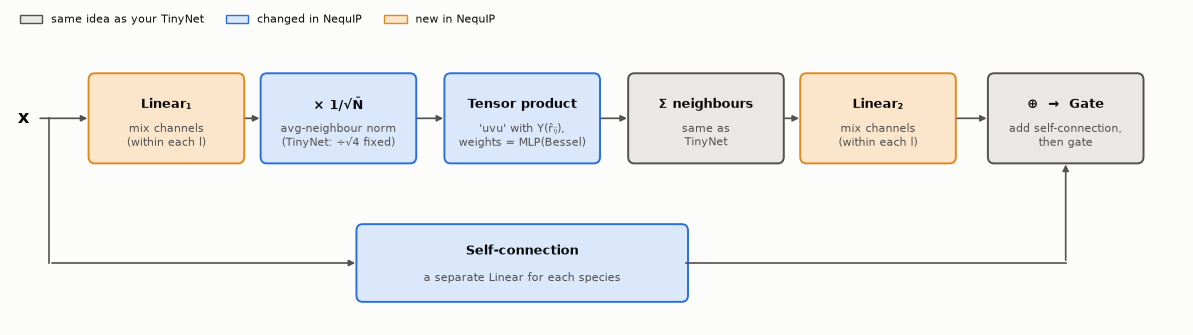

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.set_xlim(-0.6, 14.4); ax.set_ylim(0.1, 3.7); ax.axis("off")
y, w, h = 2.6, 1.95, 1.05
steps = [(1.4, "Linear₁", "mix channels\n(within each l)", "new"),
         (3.6, "× 1/√N̄", "avg-neighbour norm\n(TinyNet: ÷√4 fixed)", "changed"),
         (5.95, "Tensor product", "'uvu' with Y(r̂ᵢⱼ),\nweights = MLP(Bessel)", "changed"),
         (8.3, "Σ neighbours", "same as\nTinyNet", "same"),
         (10.5, "Linear₂", "mix channels\n(within each l)", "new"),
         (12.9, "⊕  →  Gate", "add self-connection,\nthen gate", "same")]
for x, t, s, kd in steps:
    box(ax, x, y, w, h, t, s, kd)
for (x0, *_), (x1, *_) in zip(steps, steps[1:]):
    arrow(ax, (x0 + w / 2, y), (x1 - w / 2, y))
ax.text(-0.5, y, "x", fontsize=13, va="center", weight="bold")
arrow(ax, (-0.25, y), (1.4 - w / 2, y))
box(ax, 5.95, 0.85, 4.2, 0.9, "Self-connection", "a separate Linear for each species", "changed")
ax.plot([-0.1, -0.1], [y, 0.85], color=MUTED, lw=1.2)
arrow(ax, (-0.1, 0.85), (5.95 - 2.1, 0.85))
ax.plot([5.95 + 2.1, 12.9], [0.85, 0.85], color=MUTED, lw=1.2)
arrow(ax, (12.9, 0.85), (12.9, y - h / 2))
kind_legend(ax, loc="upper left", fontsize=8, ncol=3, bbox_to_anchor=(0.0, 1.08))
plt.tight_layout(); plt.show()

### 'uvw' vs 'uvu': who talks to whom

Fix one tensor-product path, say `1o ⊗ Y¹ → 0e` (a vector channel dotted with the edge direction). Within that path:
- **TinyNet's `FullyConnectedTensorProduct` ('uvw'):** every input channel u feeds every output channel w, each pair with its own weight. That is *channels²* weights per path, and the radial MLP must output **all of them, for every edge**.
- **NequIP ('uvu'):** channel u only feeds channel u, so there is one weight per channel. This is "depthwise", like a depthwise convolution in CNNs. The cross-channel mixing is moved out of the per-edge part into **Linear₁ and Linear₂**, which run once per *atom* and have weights *shared* across all atoms.

The radial MLP runs on every edge. In a crystal with ~50 neighbours per atom, that's where the cost is. So 'uvu' makes the expensive per-edge part linear in the channel count instead of quadratic.

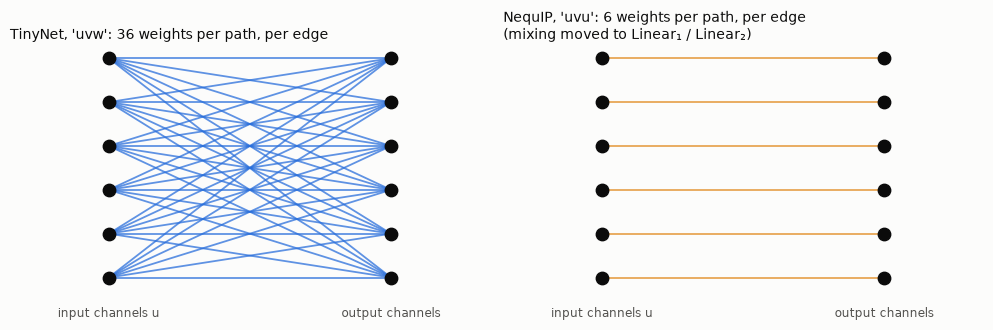

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
n = 6
for ax, mode, col in [(axs[0], "uvw", BLUE), (axs[1], "uvu", ORANGE)]:
    for u in range(n):
        for w in range(n):
            if mode == "uvw" or u == w:
                ax.plot([0, 1], [u, w], color=col, lw=1.3, alpha=0.75)
    ax.scatter([0] * n, range(n), s=80, color=INK, zorder=3); ax.scatter([1] * n, range(n), s=80, color=INK, zorder=3)
    ax.set_xlim(-0.35, 1.35); ax.axis("off")
    ax.text(0, -0.9, "input channels u", ha="center", fontsize=8.5, color=MUTED)
    ax.text(1, -0.9, "output channels", ha="center", fontsize=8.5, color=MUTED)
axs[0].set_title(f"TinyNet, 'uvw': {n*n} weights per path, per edge")
axs[1].set_title(f"NequIP, 'uvu': {n} weights per path, per edge\n(mixing moved to Linear₁ / Linear₂)")
plt.tight_layout(); plt.show()

Now the real count. We build both tensor products for a hidden layer with `m×0e + m×1o` (NequIP's lmax = 1 shape, parity off) and edge harmonics up to l = 1. `uvu_tp` mirrors the instruction-building loop in nequip's `InteractionBlock.__init__`.

channels   4:  weights per edge  uvw      64   uvu   16   ratio   4.0x
channels   8:  weights per edge  uvw     256   uvu   32   ratio   8.0x
channels  16:  weights per edge  uvw    1024   uvu   64   ratio  16.0x
channels  32:  weights per edge  uvw    4096   uvu  128   ratio  32.0x
channels  64:  weights per edge  uvw   16384   uvu  256   ratio  64.0x


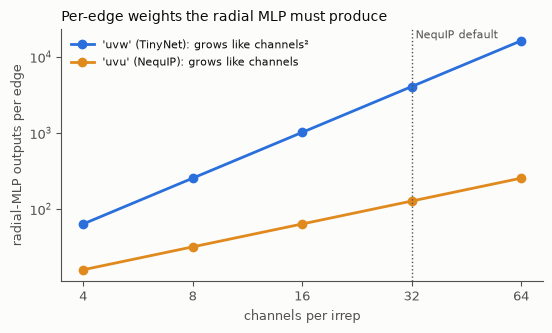

In [9]:
def tp_path_exists(irreps1, irreps2, ir_out):
    ir_out = o3.Irrep(ir_out)
    return any(ir_out in ir1 * ir2 for _, ir1 in o3.Irreps(irreps1) for _, ir2 in o3.Irreps(irreps2))

def uvu_tp(irreps_in, irreps_sh, irreps_out):
    # one path per (input irrep, edge irrep, allowed output irrep); each keeps the input's multiplicity
    irreps_in, irreps_sh, irreps_out = o3.Irreps(irreps_in), o3.Irreps(irreps_sh), o3.Irreps(irreps_out)
    irreps_mid, instructions = [], []
    for i, (mul, ir_in) in enumerate(irreps_in):
        for j, (_, ir_edge) in enumerate(irreps_sh):
            for ir_out in ir_in * ir_edge:
                if ir_out in irreps_out:
                    instructions.append((i, j, len(irreps_mid), "uvu", True))
                    irreps_mid.append((mul, ir_out))
    irreps_mid, p, _ = o3.Irreps(irreps_mid).sort()
    instructions = [(a, b, p[c], m, t) for a, b, c, m, t in instructions]
    tp = o3.TensorProduct(irreps_in, irreps_sh, irreps_mid, instructions,
                          shared_weights=False, internal_weights=False)
    return tp, irreps_mid.simplify()

sh1 = o3.Irreps.spherical_harmonics(1)
muls, n_uvw, n_uvu = [4, 8, 16, 32, 64], [], []
for m in muls:
    hid = o3.Irreps(f"{m}x0e + {m}x1o")
    n_uvw.append(o3.FullyConnectedTensorProduct(hid, sh1, hid, shared_weights=False).weight_numel)
    n_uvu.append(uvu_tp(hid, sh1, hid)[0].weight_numel)
    print(f"channels {m:3d}:  weights per edge  uvw {n_uvw[-1]:7d}   uvu {n_uvu[-1]:4d}   ratio {n_uvw[-1] / n_uvu[-1]:5.1f}x")

fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.loglog(muls, n_uvw, "o-", color=BLUE, lw=2, label="'uvw' (TinyNet): grows like channels²")
ax.loglog(muls, n_uvu, "o-", color=ORANGE, lw=2, label="'uvu' (NequIP): grows like channels")
ax.axvline(32, color=MUTED, ls=":", lw=1); ax.text(32, ax.get_ylim()[1], " NequIP default", va="top", fontsize=8, color=MUTED)
ax.set_xticks(muls, [str(m) for m in muls]); ax.minorticks_off()
ax.set_xlabel("channels per irrep"); ax.set_ylabel("radial-MLP outputs per edge")
ax.set_title("Per-edge weights the radial MLP must produce"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Correction to handoff takeaway 2.** "Weights: one per (in-channel, out-channel) pair per path, so cost scales with multiplicity²" is true for TinyNet's `FullyConnectedTensorProduct`. **NequIP doesn't use that.** Its per-edge cost is linear in the channel count, and the quadratic channel mixing happens in two cheap per-atom Linears. Same expressive idea, different place to pay for it.

### The block as code, and the one check it must pass

We assemble the block exactly as in the diagram. The gate layout (which scalars are activated, which feed gates, which irreps are gated) follows `ConvNetLayer`. As in nequip, scalars use SiLU and so do the gates.

In [10]:
class NequIPBlock(torch.nn.Module):
    def __init__(self, irreps_in, irreps_hidden, irreps_sh, n_species, num_basis=8, radial_width=32,
                 avg_num_neighbors=4.0, use_sc=True):
        super().__init__()
        irreps_in, irreps_hidden = o3.Irreps(irreps_in), o3.Irreps(irreps_hidden)
        silu = torch.nn.functional.silu
        # gate layout: keep only irreps the tensor product can actually reach (as ConvNetLayer does)
        scalars = o3.Irreps([(m, ir) for m, ir in irreps_hidden if ir.l == 0 and tp_path_exists(irreps_in, irreps_sh, ir)])
        gated = o3.Irreps([(m, ir) for m, ir in irreps_hidden if ir.l > 0 and tp_path_exists(irreps_in, irreps_sh, ir)])
        self.gate = enn.Gate(scalars, [silu] * len(scalars),
                             f"{gated.num_irreps}x0e" if gated.num_irreps else "", [silu] if gated.num_irreps else [], gated)
        irreps_conv_out = self.gate.irreps_in

        self.linear_1 = o3.Linear(irreps_in, irreps_in)
        self.tp, irreps_mid = uvu_tp(irreps_in, irreps_sh, irreps_conv_out)
        self.radial = enn.FullyConnectedNet([num_basis, radial_width, self.tp.weight_numel], silu)   # no bias, like nequip
        self.linear_2 = o3.Linear(irreps_mid, irreps_conv_out)
        # self-connection: a TP with the species one-hot = "a separate Linear for each species"
        self.sc = o3.FullyConnectedTensorProduct(irreps_in, f"{n_species}x0e", irreps_conv_out) if use_sc else None
        self.norm = avg_num_neighbors ** -0.5
        self.irreps_in, self.irreps_out = irreps_in, self.gate.irreps_out

    def forward(self, x, onehot, sh, edge_emb, src, dst):
        sc = self.sc(x, onehot) if self.sc is not None else 0
        h = self.linear_1(x) * self.norm                  # nequip normalizes *before* the sum; same thing, it's linear
        msg = self.tp(h[src], sh, self.radial(edge_emb))  # per edge
        h = torch.zeros(len(x), msg.shape[1], dtype=msg.dtype, device=msg.device).index_add(0, dst, msg)
        return self.gate(self.linear_2(h) + sc)


def radius_graph(pos, r_max, batch=None):
    dist = torch.cdist(pos, pos)
    mask = (dist < r_max) & ~torch.eye(len(pos), dtype=torch.bool, device=pos.device)
    if batch is not None:                                  # several molecules in one tensor: no edges between them
        mask &= batch[:, None] == batch[None, :]
    src, dst = mask.nonzero().T
    return src, dst

def edge_features(pos, r_max, irreps_sh, num_basis=8, batch=None):
    src, dst = radius_graph(pos, r_max, batch)
    vec = pos[dst] - pos[src]
    r = vec.norm(dim=1)
    sh = o3.spherical_harmonics(irreps_sh, vec, normalize=True, normalization="component")
    emb = bessel_basis(r, r_max, num_basis) * poly_cutoff(r, r_max)[:, None]
    return sh, emb, src, dst

def D_of(irreps, R):   # accurate Wigner-D (the matrix_exp workaround from the checkpoint notebook)
    return o3.Irreps(irreps).D_from_matrix(torch.stack([R, torch.eye(3, dtype=R.dtype)]))[0]

# the jittered SiO4 from the earlier notebooks
def sio4(jitter=0.1):
    d = 1.61 / 3**0.5
    o = d * torch.tensor([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]], dtype=torch.get_default_dtype())
    return torch.cat([torch.zeros(1, 3), o]) + jitter * torch.randn(5, 3)

torch.manual_seed(0)
pos, species = sio4(), torch.tensor([0, 1, 1, 1, 1])
onehot = torch.nn.functional.one_hot(species, 2).double()
irreps_sh2 = o3.Irreps.spherical_harmonics(2)
blk = NequIPBlock("8x0e + 8x1o + 8x2e", "8x0e + 8x1o + 8x2e", irreps_sh2, n_species=2)
x = blk.irreps_in.randn(5, -1)

R = o3.rand_matrix()
out = blk(x, onehot, *edge_features(pos, 3.0, irreps_sh2))
out_rot = blk(x @ D_of(blk.irreps_in, R).T, onehot, *edge_features(pos @ R.T, 3.0, irreps_sh2))
print("block:", blk.irreps_in, "->", blk.irreps_out)
print("rotation error |f(Rx) - D f(x)|:", (out_rot - out @ D_of(blk.irreps_out, R).T).abs().max().item(), "  <- round-off: equivariant")

block: 8x0e+8x1o+8x2e -> 8x0e+8x1o+8x2e
rotation error |f(Rx) - D f(x)|: 2.6645352591003757e-15   <- round-off: equivariant


## 4. Average-neighbour normalization: keeping feature sizes ~1

**The picture to keep:** a neighbour sum adds up N random-ish messages, and the sum of N random terms has size ~√N. One layer of that is harmless. Four layers in a dense material compound it. TinyNet hard-coded ÷√4 because SiO₄'s Si has 4 neighbours. NequIP **measures** the average neighbour count N̄ on the training set and divides by √N̄.

Below, one *untrained* 5-layer mini-NequIP (fixed weights) runs on random 40-atom clusters squeezed into smaller and smaller boxes, once without normalization and once with ÷√N̄.

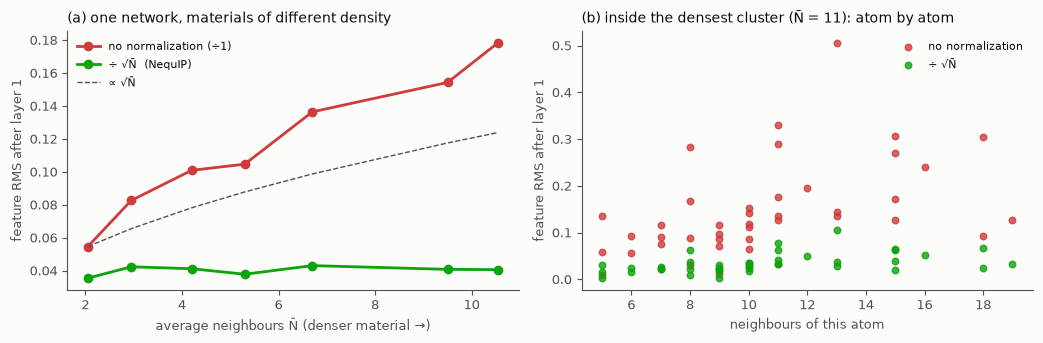

N̄ from 2.0 to 10.6:  layer-1 RMS without normalization 0.055 -> 0.178   with ÷√N̄ 0.035 -> 0.041

layer-by-layer RMS in the densest cluster (layer 0 = species embedding):


  ÷ √N̄ (correct)          0.85  0.041  0.025  0.015  0.0081  0.011


  ÷ 1 (none)               0.85  0.18  0.11  0.069  0.039  0.049


  ÷ √(N̄/100) (mis-set)    0.85  1.3  5.2  72  2.2e+04  2.5e+04


In [11]:
class MiniNequIP(torch.nn.Module):
    # nequip's layout: embed -> (num_layers-1) blocks with lmax features -> last block scalars only -> readout -> scale/shift -> sum
    def __init__(self, n_species=2, lmax=1, mul=16, num_layers=3, r_max=2.0, num_basis=8,
                 radial_width=32, avg_num_neighbors=4.0, shift=0.0, scale=1.0):
        super().__init__()
        self.r_max, self.num_basis, self.n_species = r_max, num_basis, n_species
        self.irreps_sh = o3.Irreps.spherical_harmonics(lmax)
        hidden = o3.Irreps([(mul, (l, (-1) ** l)) for l in range(lmax + 1)])     # parity off: 0e, 1o, 2e, ...
        self.embed = o3.Linear(f"{n_species}x0e", f"{mul}x0e")
        layers, irreps = [], o3.Irreps(f"{mul}x0e")
        for i in range(num_layers):
            out = hidden if i < num_layers - 1 else o3.Irreps(f"{mul}x0e")
            b = NequIPBlock(irreps, out, self.irreps_sh, n_species, num_basis, radial_width,
                            avg_num_neighbors, use_sc=i > 0)                     # nequip: no self-connection in layer 0
            layers.append(b); irreps = b.irreps_out
        self.layers = torch.nn.ModuleList(layers)
        self.readout = o3.Linear(irreps, "1x0e")
        self.register_buffer("shift", torch.full((n_species,), float(shift)))
        self.register_buffer("scale", torch.full((n_species,), float(scale)))

    def energy(self, pos, species, batch, n_graphs, return_features=False):
        sh, emb, src, dst = edge_features(pos, self.r_max, self.irreps_sh, self.num_basis, batch)
        onehot = torch.nn.functional.one_hot(species, self.n_species).to(pos.dtype)
        x = self.embed(onehot)
        feats = [x]
        for layer in self.layers:
            x = layer(x, onehot, sh, emb, src, dst); feats.append(x)
        e_atom = self.readout(x).squeeze(-1) * self.scale[species] + self.shift[species]
        E = torch.zeros(n_graphs, dtype=pos.dtype, device=pos.device).index_add(0, batch, e_atom)
        return (E, feats) if return_features else E

    def forward(self, pos, species, batch, n_graphs):
        pos = pos if pos.requires_grad else pos.clone().requires_grad_(True)
        E = self.energy(pos, species, batch, n_graphs)
        F = -torch.autograd.grad(E.sum(), pos, create_graph=self.training)[0]   # create_graph: train on forces
        return E, F


def random_cluster(n=40, box=8.0, min_dist=1.2, seed=0):
    g, pts = torch.Generator().manual_seed(seed), []
    while len(pts) < n:
        p = torch.rand(3, generator=g) * box
        if all((p - q).norm() > min_dist for q in pts):
            pts.append(p)
    return torch.stack(pts)

def layer_features(pos, species, avg, num_layers=5, seed=7):
    torch.manual_seed(seed)                                    # identical weights for every call
    m = MiniNequIP(lmax=1, mul=16, num_layers=num_layers, r_max=3.5, avg_num_neighbors=avg)
    with torch.no_grad():
        _, feats = m.energy(pos, species, torch.zeros(len(pos), dtype=torch.long), 1, return_features=True)
    return feats
rms_of = lambda f: f.pow(2).mean().sqrt().item()

# 40-atom random clusters, from sparse (gas-like) to dense (close-packed-like)
sp40 = torch.randint(0, 2, (40,), generator=torch.Generator().manual_seed(1))
nbar, raw, normed = [], [], []
for box_len in [14.0, 12.0, 10.5, 9.5, 8.5, 7.5, 6.8]:
    p = random_cluster(box=box_len)
    src, dst = radius_graph(p, 3.5)
    nbar.append(len(src) / 40)
    raw.append(rms_of(layer_features(p, sp40, 1.0)[1]))           # layer-1 output, no normalization
    normed.append(rms_of(layer_features(p, sp40, nbar[-1])[1]))   # layer-1 output, ÷ √N̄ of that structure
dense = p
n_nb = torch.bincount(radius_graph(dense, 3.5)[1], minlength=40)

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.5))
nb_ = np.array(nbar)
axs[0].plot(nb_, raw, "o-", color=CRITICAL, lw=2, label="no normalization (÷1)")
axs[0].plot(nb_, normed, "o-", color=GOOD, lw=2, label="÷ √N̄  (NequIP)")
axs[0].plot(nb_, raw[0] * np.sqrt(nb_ / nb_[0]), ls="--", color=MUTED, lw=1, label="∝ √N̄")
axs[0].set_xlabel("average neighbours N̄ (denser material →)"); axs[0].set_ylabel("feature RMS after layer 1")
axs[0].set_title("(a) one network, materials of different density"); axs[0].legend(frameon=False, fontsize=8)
for avg, col, lab in [(1.0, CRITICAL, "no normalization"), (nbar[-1], GOOD, "÷ √N̄")]:
    per_atom = layer_features(dense, sp40, avg)[1].pow(2).mean(1).sqrt()
    axs[1].scatter(np_(n_nb), np_(per_atom), color=col, s=22, alpha=0.8, label=lab)
axs[1].set_xlabel("neighbours of this atom"); axs[1].set_ylabel("feature RMS after layer 1")
axs[1].set_title(f"(b) inside the densest cluster (N̄ = {nbar[-1]:.0f}): atom by atom"); axs[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f"N̄ from {nbar[0]:.1f} to {nbar[-1]:.1f}:  layer-1 RMS without normalization {raw[0]:.3f} -> {raw[-1]:.3f}"
      f"   with ÷√N̄ {normed[0]:.3f} -> {normed[-1]:.3f}")
print("\nlayer-by-layer RMS in the densest cluster (layer 0 = species embedding):")
for lab, avg in [("÷ √N̄ (correct)", nbar[-1]), ("÷ 1 (none)", 1.0), ("÷ √(N̄/100) (mis-set)", nbar[-1] / 100)]:
    print(f"  {lab:24s}", "  ".join(f"{rms_of(f):.2g}" for f in layer_features(dense, sp40, avg)))

**Reading it:**
- **Panel (a):** the same untrained network, run on sparser and denser materials. Without normalization the first layer's output grows like √N̄ (red, following the dashed line). With ÷√N̄ (green) it's about the same size at every density. That's what NequIP buys: the network starts training with features of the size it was designed for, whether your data is a molecule (N̄ ≈ 3) or a dense crystal (α-quartz has roughly 40 neighbours per atom within 5 Å).
- **Panel (b):** inside one structure, atoms with more neighbours still get bigger features, *even with* normalization. That's deliberate: dividing by one constant rescales everything but keeps the coordination signal (see below).
- **The layer-by-layer printout:** in this mini model the gap stays at about √N̄ rather than compounding. That's because the self-connection carries each atom's own features forward with no neighbour sum in it. But if the per-layer gain is too large, as in the mis-set row, it does compound: ×4 or more per layer, about 30,000× bigger by the last layer here. Normalization keeps every layer's gain near 1.

**Why √N̄ and not N (a mean)?** A mean would make 2 neighbours and 12 neighbours look alike, which throws away coordination number. For silica, 4-fold vs 6-fold Si (quartz vs stishovite) is exactly the physics you care about. Dividing by a *constant* √N̄ keeps the sum (so the count stays visible) and only fixes the overall scale.

**For SiO₂:** Si has ~4 neighbours and O has ~2. nequip 0.19.1 accepts `avg_num_neighbors` as a **per-species dict**, so each species is normalized by its own typical count. Quiz question 3 at the end is about this.

## 5. Readout, per-species scale and shift, and a toy potential to train on

**Readout.** The last block outputs only scalars (`32x0e` by default). One Linear turns them into a single number ẽᵢ per atom.

**Scale and shift.** The network's natural output is ~1. Real energies aren't: MD17 total energies are large negative numbers, the energy of all electrons, and the interesting variation is a tiny fraction of that. So NequIP writes each atom's energy as

    Eᵢ = scale[species] · ẽᵢ + shift[species]

nequip's own docs recommend:
- **shift:** the isolated-atom reference energy, or the average per-atom energy of the data
- **scale:** the force RMS of the data

Then the network only has to learn O(1) corrections. It's the same idea as standardizing regression targets, done per species. These two parameters are *not* trained by default.

### A toy SiO₄ potential with a known answer

To see what each lmax can learn, we need data where we *know* the true function. Our toy energy has two parts:
- **bond stretch:** 20 · Σ (r − 1.61)²
- **angle bend:** 20 · Σ over the 6 O–Si–O pairs of (cos θ + 1/3)², where cos θ = −1/3 is the ideal 109.47° tetrahedral angle

We use r_max = 2.0 Å, so each Si sees its 4 O, but **O–O pairs are outside the cutoff**. The only way to know an angle is from the *directions* of the Si–O bonds. A distance-only model can't know them.

In [12]:
TET = torch.tensor([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]], dtype=torch.float64) / 3**0.5
R_MAX, K_BOND, K_ANG = 2.0, 20.0, 20.0

def sample_sio4(n, bond_sigma=0.04, dir_sigma=0.12, seed=0):
    # random tetrahedra: bonds 1.61 ± 0.04 Å, bond directions wobbled by ~7°, random orientation and position.
    # Rejection keeps every Si-O well inside r_max and every O-O outside it.
    g, out = torch.Generator().manual_seed(seed), []
    while len(out) < n:
        u = TET + dir_sigma * torch.randn(4, 3, generator=g)
        u = u / u.norm(dim=1, keepdim=True)
        p = torch.cat([torch.zeros(1, 3), (1.61 + bond_sigma * torch.randn(4, 1, generator=g)) * u])
        Q, _ = torch.linalg.qr(torch.randn(3, 3, generator=g))
        p = p @ Q.T + 3 * torch.randn(1, 3, generator=g)
        d = torch.cdist(p, p)
        if d[0, 1:].max() < R_MAX - 0.15 and d[1:, 1:][torch.triu(torch.ones(4, 4, dtype=torch.bool), 1)].min() > R_MAX:
            out.append(p)
    return torch.stack(out)                                                    # (n, 5, 3), atom 0 = Si

def bond_dirs(pos):
    v = pos[:, 1:] - pos[:, :1]
    return v.norm(dim=-1), v / v.norm(dim=-1, keepdim=True)

def toy_energy(pos):
    r, u = bond_dirs(pos)
    cos = u @ u.transpose(1, 2)
    iu = torch.triu_indices(4, 4, 1)
    return K_BOND * ((r - 1.61) ** 2).sum(-1) + K_ANG * ((cos[:, iu[0], iu[1]] + 1 / 3) ** 2).sum(-1)

def forces_of(energy_fn, pos):
    pos = pos.clone().requires_grad_(True)
    return -torch.autograd.grad(energy_fn(pos).sum(), pos)[0]

data = sample_sio4(500)
E_true, F_true = toy_energy(data).detach(), forces_of(toy_energy, data)
d = torch.cdist(data, data)
print(f"500 configurations | Si-O {d[:, 0, 1:].min():.2f}–{d[:, 0, 1:].max():.2f} Å (< r_max)"
      f" | closest O-O {d[:, 1:, 1:][d[:, 1:, 1:] > 0].min():.2f} Å (> r_max {R_MAX})")
print(f"energy {E_true.mean():.2f} ± {E_true.std():.2f}   force RMS {F_true.pow(2).mean().sqrt():.2f}")

500 configurations | Si-O 1.46–1.74 Å (< r_max) | closest O-O 2.07 Å (> r_max 2.0)
energy 3.19 ± 1.90   force RMS 5.19


## 6. lmax: what one atom can "see" about its neighbours

**The picture to keep.** Stand on the Si and look out. You see 4 bright dots on your sky, one per O direction. The spherical harmonics of order l are a "lens" that sees only shapes of a certain complexity:
- **l = 0** sees only *how many* dots there are (a ball)
- **l = 1** sees whether the dots are **lopsided**, i.e. bunched to one side (an arrow pointing toward the bunch)
- **l = 2** sees whether the arrangement is **stretched or squashed** along an axis (a cloverleaf or dumbbell)
- **l = 3** sees finer patterns. A perfect tetrahedron *is* an l = 3 pattern.

In the code, each "lens" image is Σᵢ Y_l(ûᵢ), the sum of the edge harmonics over the 4 bonds. Up to the radial weights, which are all equal here because every bond has the same length, that's what the first tensor product computes at the Si. Below are three tetrahedra with **identical bond lengths** (the faint ghost behind the distorted ones is the perfect tetrahedron):
- **perfect**
- **squashed** along z
- **lopsided**, with two O pulled toward each other

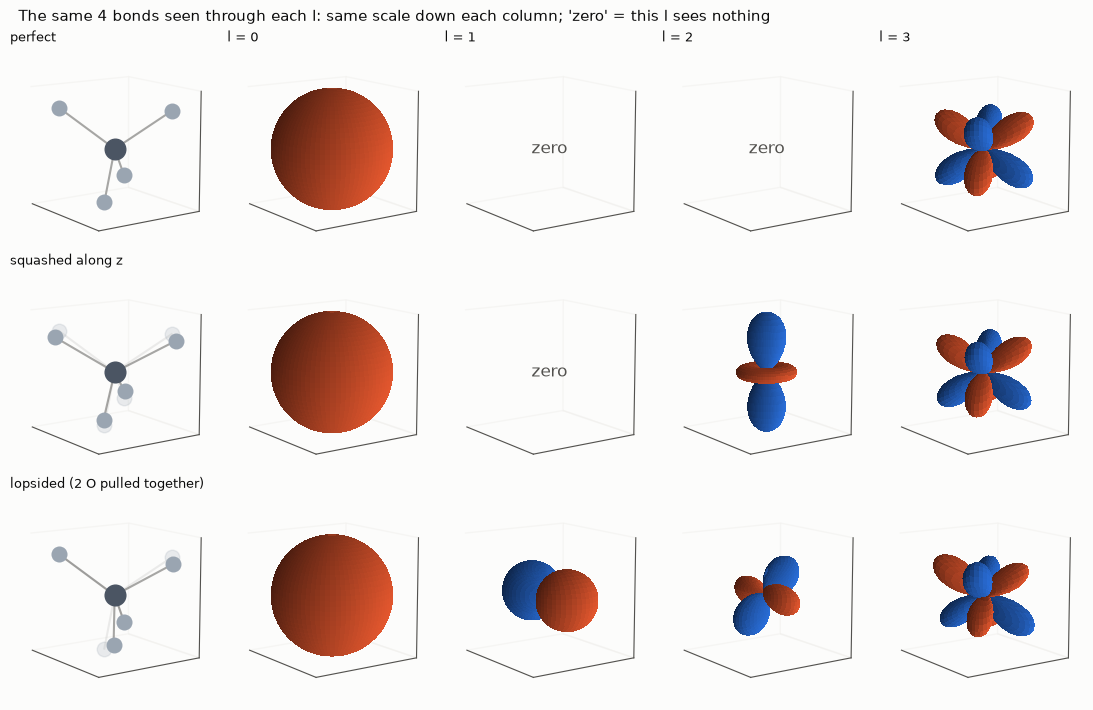

In [13]:
def tetra(u, r=1.61):
    u = u / u.norm(dim=1, keepdim=True)
    return torch.cat([torch.zeros(1, 3), r * u])

def rot_toward(a, b, ang):           # turn unit vector a toward b by ang (radians), in their common plane
    w = b - (a @ b) * a
    return math.cos(ang) * a + math.sin(ang) * w / w.norm()

perfect = tetra(TET)
squashed = tetra(TET * torch.tensor([1.0, 1.0, 0.78]))
lop = TET.clone()
lop[0], lop[1] = rot_toward(TET[0], TET[1], math.radians(9)), rot_toward(TET[1], TET[0], math.radians(9))
lopsided = tetra(lop)
shapes = {"perfect": perfect, "squashed along z": squashed, "lopsided (2 O pulled together)": lopsided}

def neighbour_image(pos, l):          # f(u) = Σ_i Y_l(û_i) · Y_l(u): the 4 bonds seen through the "l lens"
    _, u = bond_dirs(pos[None])
    Yb = o3.spherical_harmonics(l, u[0], normalize=True, normalization="component")       # (4, 2l+1)
    Yu = o3.spherical_harmonics(l, U.reshape(-1, 3), normalize=True, normalization="component")
    return (Yu @ Yb.sum(0)).reshape(U.shape[:2])

imgs = {name: [neighbour_image(p, l) for l in range(4)] for name, p in shapes.items()}
ref = [max(imgs[n][l].abs().max().item() for n in imgs) for l in range(4)]     # same scale per column

fig = plt.figure(figsize=(11, 7.2))
for row, (name, p) in enumerate(shapes.items()):
    ax = ax3d(fig, 3, 5, 5 * row + 1, title=name, lim=1.4, elev=12, azim=-35)
    if row > 0:
        draw_molecule(ax, perfect, alpha=0.2)                            # faint ghost: the perfect tetrahedron
    draw_molecule(ax, p)
    for l in range(4):
        ax = ax3d(fig, 3, 5, 5 * row + 2 + l, title=f"l = {l}" if row == 0 else "", lim=1.0, elev=12, azim=-35)
        draw_glyph(ax, imgs[name][l], ref[l])
fig.suptitle("The same 4 bonds seen through each l: same scale down each column; 'zero' = this l sees nothing",
             x=0.02, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

**What to notice:**
- **l = 0** is the same ball in all three rows. All have 4 bonds of the same length, so a distance-only view **can't tell them apart at all**.
- **l = 1 and l = 2 are exactly zero for the perfect tetrahedron.** Its symmetry forces that, the same "symmetry-forced zeros" idea as in the checkpoint notebook.
- **Squashed:** l = 1 is *still zero*, because the dots aren't bunched to one side, but l = 2 lights up as a dumbbell along z. So **an l = 1 view also sees nothing**.
- **Lopsided:** l = 1 lights up (an arrow toward the pulled-together pair) and so does l = 2.

### The angle energy splits exactly into these two lenses

With S = Σ ûᵢ (the l = 1 image, "lopsidedness") and T = the traceless part of Σ ûᵢûᵢᵀ (the l = 2 image, "stretch"), a few lines of algebra give

    E_angle = K · ( |S|² / 3  +  |T|² / 2 )

There is no l = 0 term, and nothing beyond l = 2. Let's check it numerically, then predict:
- **lmax = 0** can learn none of E_angle
- **lmax = 1** can learn the |S|² part
- **lmax = 2** can learn all of it

In [14]:
def angle_parts(pos):
    _, u = bond_dirs(pos)
    S = u.sum(1)                                                         # l = 1 image: lopsidedness
    M = torch.einsum("bia,bic->bac", u, u)
    T = M - M.diagonal(dim1=1, dim2=2).sum(-1)[:, None, None] / 3 * torch.eye(3)   # l = 2 image: stretch
    return K_ANG * S.pow(2).sum(-1) / 3, K_ANG * T.pow(2).sum((-1, -2)) / 2

def angle_energy(pos):
    r, _ = bond_dirs(pos)
    return toy_energy(pos) - K_BOND * ((r - 1.61) ** 2).sum(-1)

e_l1, e_l2 = angle_parts(data)
print("E_angle - (l=1 part + l=2 part), max over 500 configs:", (angle_energy(data) - e_l1 - e_l2).abs().max().item())
for name, p in shapes.items():
    a, b = angle_parts(p[None])
    print(f"{name:32s} l=1 part {a.item():6.3f}   l=2 part {b.item():6.3f}   E_angle {angle_energy(p[None]).item():6.3f}")

E_angle - (l=1 part + l=2 part), max over 500 configs: 3.9968028886505635e-15
perfect                          l=1 part  0.000   l=2 part  0.000   E_angle  0.000
squashed along z                 l=1 part  0.000   l=2 part  2.404   E_angle  2.404
lopsided (2 O pulled together)   l=1 part  0.388   l=2 part  1.893   E_angle  2.281


## 7. The experiment: train lmax = 0, 1, 2 on the same data

Same mini-NequIP each time: 3 blocks, 16 channels per irrep, the Bessel basis and all of the above. **Only lmax changes.** The loss weights energy (per atom) and forces, as NequIP does. Forces come from −∂E/∂x, so training needs a gradient *of* a gradient (`create_graph=True`).

400 configurations for training, 100 held out. It runs on the GPU in float64: about 2 minutes in total on the GTX 1650 Ti.

In [15]:
n_train = 400
sp = torch.tensor([0, 1, 1, 1, 1])
def to_batch(idx):
    B = len(idx)
    return dict(pos=data[idx].reshape(-1, 3).to(DEVICE), species=sp.repeat(B).to(DEVICE),
                batch=torch.arange(B).repeat_interleave(5).to(DEVICE), n=B,
                E=E_true[idx].to(DEVICE), F=F_true[idx].reshape(-1, 3).to(DEVICE))
train_set, val_set = to_batch(torch.arange(n_train)), to_batch(torch.arange(n_train, 500))

shift = (E_true[:n_train].mean() / 5).item()                 # mean per-atom energy
scale = F_true[:n_train].pow(2).mean().sqrt().item()         # force RMS, as nequip's docs suggest

def force_rmse(model, s):
    model.eval()
    E, F = model(s["pos"], s["species"], s["batch"], s["n"])
    return (F - s["F"]).pow(2).mean().sqrt().item(), (E - s["E"]).abs().mean().item()

def train(lmax, steps=400, lr=5e-3, seed=1):
    torch.manual_seed(seed)
    model = MiniNequIP(lmax=lmax, mul=16, num_layers=3, r_max=R_MAX, shift=shift, scale=scale).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    curve, t0 = [], time.time()
    for step in range(steps + 1):
        if step % 10 == 0:
            curve.append((step, *force_rmse(model, val_set)))
        if step == steps:
            break
        model.train()
        E, F = model(train_set["pos"], train_set["species"], train_set["batch"], train_set["n"])
        loss = ((E - train_set["E"]) / 5).pow(2).mean() + (F - train_set["F"]).pow(2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"lmax={lmax}: {time.time() - t0:5.1f} s   val force RMSE {curve[-1][1]:.3f}   val energy MAE {curve[-1][2]:.3f}")
    return model.cpu().eval(), np.array(curve)

models, curves = {}, {}
for lmax in [0, 1, 2]:
    models[lmax], curves[lmax] = train(lmax)

lmax=0:  15.9 s   val force RMSE 5.115   val energy MAE 1.602


lmax=1:  29.3 s   val force RMSE 2.989   val energy MAE 1.057


lmax=2:  78.6 s   val force RMSE 0.451   val energy MAE 0.037


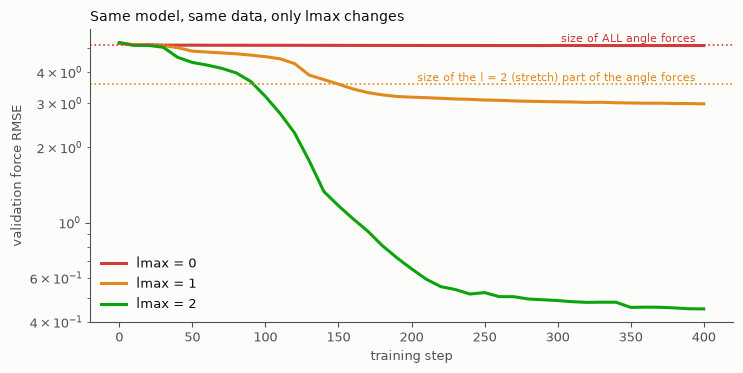

In [16]:
val_pos = data[n_train:]
F_ang = forces_of(angle_energy, val_pos)                              # what a distance-only model cannot see
F_l2 = forces_of(lambda p: angle_parts(p)[1], val_pos)               # what an lmax=1 view cannot see
rms = lambda F: F.pow(2).mean().sqrt().item()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
cols = {0: CRITICAL, 1: ORANGE, 2: GOOD}
for lmax, c in curves.items():
    ax.semilogy(c[:, 0], c[:, 1], color=cols[lmax], lw=2.2, label=f"lmax = {lmax}")
ax.axhline(rms(F_ang), color=CRITICAL, ls=":", lw=1.2)
ax.text(400, rms(F_ang), "size of ALL angle forces  ", color=CRITICAL, ha="right", va="bottom", fontsize=8)
ax.axhline(rms(F_l2), color=ORANGE, ls=":", lw=1.2)
ax.text(400, rms(F_l2), "size of the l = 2 (stretch) part of the angle forces  ", color=ORANGE, ha="right", va="bottom", fontsize=8)
ax.set_xlabel("training step"); ax.set_ylabel("validation force RMSE")
ax.set_title("Same model, same data, only lmax changes"); ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

**Reading the curves:**
- **Red (lmax = 0)** flattens out almost immediately, at the red dotted line. Its error *is* the full angle force: it learned the bond stretch (a distance) and nothing else. More training can't help, because the information isn't in its inputs.
- **Orange (lmax = 1)** gets past that, but stalls not far below the orange dotted line, the size of the forces from the l = 2 "stretch" part. It recovers a little of the stretch indirectly: in later layers each O receives Si's features and combines them with its own bond direction. But most of what's left is the stretch, as the next cell shows.
- **Green (lmax = 2)** keeps going down. Everything in this potential is visible to it.

The next cell makes the claim sharper. If lmax = 1 mostly misses the stretch part, then its force **errors** should point mostly the same way as the stretch-part forces. The picture after that tests the blind spots directly.

lmax=0: its force error vs the angle forces      : cosine similarity 0.99
lmax=1: its force error vs the l=2 (stretch) part: cosine similarity 0.80
(1.00 = the error is exactly that missing piece)


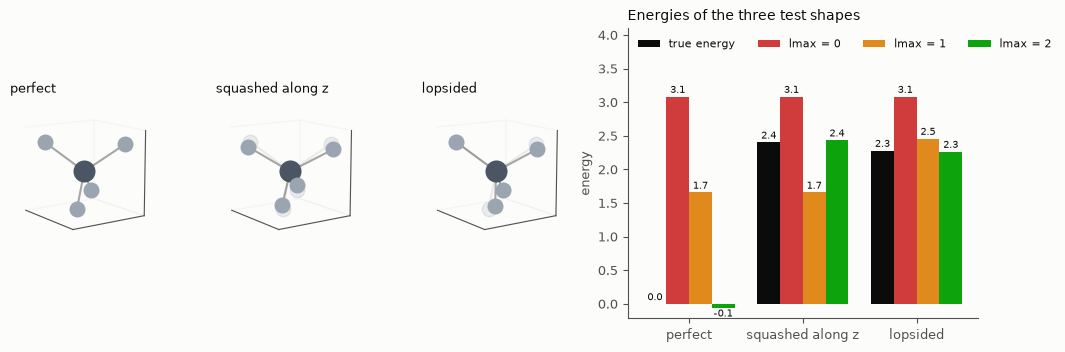

lmax=0: E(squashed) - E(perfect) = +3.6e-15   (true: +2.40)
lmax=1: E(squashed) - E(perfect) = -1.8e-15   (true: +2.40)


In [17]:
def predict(model, pos_batch):
    B = len(pos_batch)
    return model(pos_batch.reshape(-1, 3), sp.repeat(B), torch.arange(B).repeat_interleave(5), B)

cos_sim = lambda a, b: (a * b).sum().item() / (a.norm() * b.norm()).item()
_, F0 = predict(models[0], val_pos); _, F1 = predict(models[1], val_pos)
print(f"lmax=0: its force error vs the angle forces      : cosine similarity {cos_sim(F_true[n_train:].reshape(-1, 3) - F0.reshape(-1, 3), F_ang.reshape(-1, 3)):.2f}")
print(f"lmax=1: its force error vs the l=2 (stretch) part: cosine similarity {cos_sim(F_true[n_train:].reshape(-1, 3) - F1.reshape(-1, 3), F_l2.reshape(-1, 3)):.2f}")
print("(1.00 = the error is exactly that missing piece)")

names = list(shapes)
P = torch.stack([shapes[n] for n in names])
E_exact = toy_energy(P)
E_pred = {l: predict(models[l], P)[0].detach() for l in models}

fig = plt.figure(figsize=(11, 3.6))
for i, n in enumerate(names):
    ax = ax3d(fig, 1, 5, i + 1, title=n.split(" (")[0], lim=1.4, elev=12, azim=-35)
    if i > 0:
        draw_molecule(ax, perfect, alpha=0.2)
    draw_molecule(ax, P[i])
ax = fig.add_subplot(1, 5, (4, 5))
xs, wbar = np.arange(3), 0.2
bars = [ax.bar(xs - 1.5 * wbar, np_(E_exact), wbar, color=INK, label="true energy")]
for j, l in enumerate([0, 1, 2]):
    bars.append(ax.bar(xs + (j - 0.5) * wbar, np_(E_pred[l]), wbar, color=cols[l], label=f"lmax = {l}"))
for b in bars:
    ax.bar_label(b, fmt="%.1f", fontsize=7, padding=1)
ax.set_xticks(xs, [n.split(" (")[0] for n in names]); ax.set_ylabel("energy"); ax.set_ylim(top=4.1)
ax.set_title("Energies of the three test shapes"); ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper left")
plt.tight_layout(); plt.show()
for l in [0, 1]:
    print(f"lmax={l}: E(squashed) - E(perfect) = {(E_pred[l][1] - E_pred[l][0]).item():+.1e}"
          f"   (true: {(E_exact[1] - E_exact[0]).item():+.2f})")

**The blind spots, made exact:**
- **lmax = 0** gives all three shapes the **same** energy, up to round-off. It sees 4 equal bond lengths and nothing else.
- **lmax = 1** gives perfect and squashed the **same** energy, up to round-off. Neither shape is lopsided, so every vector this network can form at Si is zero for both, and the indirect route through the O atoms has nothing to work with either. It *does* react to the lopsided one.
- **lmax = 2** separates all three.

These aren't "the model hasn't trained enough" errors. They're "the model **cannot represent** the difference" errors, and you can only see the difference with a picture of what each l captures.

**What this means for choosing lmax:**
- **NequIP's default lmax = 1 is a good trade-off for many systems.** Real models have more layers, and parity-on features (0o, 1e) let information take more indirect routes. Real potentials also mix many effects. The NequIP paper's lmax ablation shows the largest jump going from l = 0 to l = 1.
- **But if the physics lives in a shape**, lmax = 2 can matter. Examples: polyhedral distortions, like SiO₄ tetrahedra squashing under pressure, or octahedral tilts. The cost goes up quickly with lmax, so test 1 vs 2 on your data.
- **This is also the door to MACE** (the `mace-mp-0.pdf` in your papers folder). MACE builds products of these neighbour images at one atom, i.e. higher **body order**, instead of relying on many layers to combine them. That's for a later session.

## 8. Symmetry checks on the trained model: one per row of the warm-up table

Now the payoff from the warm-up quiz. We take the **trained** lmax = 2 model and check each property against the symmetry that guarantees it:

| Symmetry of the energy | What it guarantees | How we check it |
|---|---|---|
| shift the molecule | forces sum to zero | ΣF |
| rotate the molecule | torques sum to zero, **and** forces turn with the molecule | Σ r × F, and F(rotated) vs rotated F |
| reflect (invert) the molecule | forces flip like true vectors (1o) | F(−x) vs −F(x) |
| forces = −∂E/∂x | no energy drift | the Jacobian of F is symmetric (checkpoint notebook §13) |

First the picture: the forces on a validation molecule, and on the same molecule rotated, with the second set rotated back for comparison.

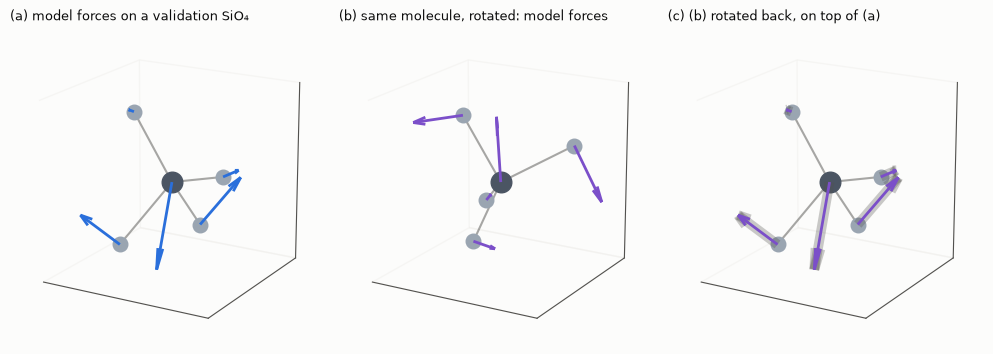

In [18]:
m2 = models[2]
p0 = val_pos[0]
one = lambda p: predict(m2, p[None])
Rm = o3.rand_matrix()
E0, F0 = one(p0); Er, Fr = one(p0 @ Rm.T)

fig = plt.figure(figsize=(10, 3.8))
c0 = p0[0]
ax = ax3d(fig, 1, 3, 1, title="(a) model forces on a validation SiO₄", lim=1.8, center=np_(c0))
draw_molecule(ax, p0); draw_arrows(ax, p0, F0, BLUE, scale=0.12)
ax = ax3d(fig, 1, 3, 2, title="(b) same molecule, rotated: model forces", lim=1.8, center=np_(c0 @ Rm.T))
draw_molecule(ax, p0 @ Rm.T); draw_arrows(ax, p0 @ Rm.T, Fr, PURPLE, scale=0.12)
ax = ax3d(fig, 1, 3, 3, title="(c) (b) rotated back, on top of (a)", lim=1.8, center=np_(c0))
draw_molecule(ax, p0); draw_arrows(ax, p0, F0, MUTED, scale=0.12, lw=7, alpha=0.3)
draw_arrows(ax, p0, Fr @ Rm, PURPLE, scale=0.12)
plt.tight_layout(); plt.show()

In [19]:
t = torch.randn(3) * 5
inv = -torch.eye(3)
Et, Ft = one(p0 + t)
Ei, Fi = one(p0 @ inv.T)
torque = torch.linalg.cross(p0, F0).sum(0)

# Jacobian of F wrt positions: symmetric if F = -dE/dx
m2.train()                                   # train mode only switches on create_graph, so F stays differentiable
J = torch.autograd.functional.jacobian(lambda p: one(p.reshape(5, 3))[1].reshape(-1), p0.reshape(-1))
m2.eval()
rows = [("translation", "energy unchanged", (Et - E0).abs().max()),
        ("translation", "ΣF = 0", F0.sum(0).abs().max()),
        ("rotation", "energy unchanged", (Er - E0).abs().max()),
        ("rotation", "forces turn with the molecule", (Fr - F0 @ Rm.T).abs().max()),
        ("rotation", "Σ r × F = 0 (net torque)", torque.abs().max()),
        ("inversion", "energy unchanged", (Ei - E0).abs().max()),
        ("inversion", "forces flip (true vectors)", (Fi + F0).abs().max()),
        ("F = −∂E/∂x", "Jacobian symmetric", (J - J.T).abs().max())]
scale_F = F0.abs().max().item()
print(f"force scale on this molecule: {scale_F:.2f}   (look at the exponent relative to this)\n")
for sym, prop, err in rows:
    print(f"{sym:12s} {prop:32s} {err.item():.1e}")

force scale on this molecule: 13.16   (look at the exponent relative to this)

translation  energy unchanged                 0.0e+00
translation  ΣF = 0                           1.1e-15
rotation     energy unchanged                 9.3e-15
rotation     forces turn with the molecule    1.5e-13
rotation     Σ r × F = 0 (net torque)         7.1e-15
inversion    energy unchanged                 0.0e+00
inversion    forces flip (true vectors)       0.0e+00
F = −∂E/∂x   Jacobian symmetric               1.5e-12


Every error is 1e-12 or smaller (several are exactly 0), against forces of size ~10. That's float64 round-off, about 13 orders of magnitude below a real violation. The largest two (the rotation test and the Jacobian) go through the most arithmetic, which is the same exponent-reading habit as before. And this time the network is **trained**, so its forces are meaningful (validation error ~0.45 against a force RMS of ~5) as well as symmetric.

Notice **why** each row passes, because none of them was trained in:
- **translation:** the model only ever sees edge vectors pos[dst] − pos[src]
- **rotation and inversion:** e3nn's harmonics and tensor products, with parity bookkeeping
- **conservation:** the forces are a gradient of the energy

That's the whole NequIP design argument in one table. Training only decides *which* symmetric, conservative function you get.

---

## Recap

| Paper piece | What it is, in one picture | Why NequIP does it |
|---|---|---|
| Bessel × polynomial cutoff | standing waves bent to arrive flat at r_max | smooth forces when atoms cross the cutoff → no MD kicks |
| 'uvu' TP + Linear₁/₂ | one line per channel, mixing moved per-atom | per-edge cost linear in channels instead of quadratic |
| ÷ √N̄ | features stay ~1 at every depth | stable training in dense materials; coordination still visible |
| per-species self-connection, scale and shift | each element gets its own skip path and energy offset | O(1) learning targets; element-specific chemistry |
| lmax | the "lens": l = 1 sees lopsided, l = 2 sees stretched | angular physics the distances alone can't express |

## Quiz (answer in chat, letters are fine)

**1.** An atom drifts across r_max in a model using the Bessel basis but **no** polynomial envelope. What happens?
- A) The energy jumps
- B) The energy is continuous, but the force jumps
- C) Both are smooth, because the Bessel functions are 0 at r_max
- D) Nothing, because the atom has left the graph

**2.** You double the channels from 32 to 64. Roughly how does the number of radial-MLP outputs **per edge** change?
- A) Both 'uvw' and 'uvu' double
- B) 'uvu' doubles, 'uvw' quadruples
- C) Both quadruple
- D) 'uvu' quadruples, 'uvw' doubles

**3.** In silica, Si has ~4 neighbours and O has ~2. The global average is (1·4 + 2·2)/3 ≈ 2.7. With a single global N̄, what goes wrong, and what does a per-species N̄ fix?
- A) Nothing: √N̄ is just a constant, and training absorbs it
- B) Si's summed features come out ~√(4/2.7) too big and O's ~√(2/2.7) too small. Per-species N̄ brings both to ~1.
- C) O atoms get more weight in the energy than Si
- D) Coordination number becomes invisible to the model

**4.** A squashed SiO₄ (all bonds equal, no lopsidedness) has higher energy than the perfect one. What is the smallest lmax at which a **single Si-centred neighbour sum** can tell them apart?
- A) 0
- B) 1
- C) 2
- D) 3

## Next

1. Install nequip 0.19.1 in a **separate** environment first (dry run), so this one stays intact. Then pick a small MD17 molecule.
2. Train with the Hydra/Lightning config, starting from lmax = 1 with small channel counts, on the GPU.
3. Point §8's table at the trained nequip model.